# Counting cycle days against the estimated day of ovulation

Studies of the menstrual cycle often schedule a test session by counting days, for example day 14 for ovulation or day 21 for the mid-luteal phase. How often does a counted day land in the intended phase, and how much does a miss weaken a phase comparison?

**Data.** Marquette University menstrual cycle data (Fehring 2012, "Menstrual Cycle Data", [epublications.marquette.edu/data_nfp/7](https://epublications.marquette.edu/data_nfp/7)), collected in a randomised comparison of two internet-supported fertility awareness methods (Fehring et al. 2013, *Contraception* 88:24–30, [doi:10.1016/j.contraception.2012.10.010](https://doi.org/10.1016/j.contraception.2012.10.010)). The file `FedCycleData071012.csv` holds 1665 cycles of 159 women, with cycle length and an estimated day of ovulation derived from the fertility signs each woman recorded (a urinary hormone monitor in one study arm, cervical mucus in the other). Ovulation was not confirmed by ultrasound or progesterone. The file has to be downloaded from the page above by hand; set `MARQUETTE` to its path or place it in `data/marquette/`.

1. **Variation.** Day of ovulation and luteal phase length, within and between women.
2. **Counting rules.** Error of three rules for the day of ovulation: day 14, 14 days before the next menstruation expected from the woman's previous cycles, and 14 days before the actual next menstruation (only known afterwards).
3. **Scheduled sessions.** Share of sessions that fall in the periovulatory window and in the mid-luteal window under each rule.
4. **Consequence for sample size.** How much larger a study would need to be to keep its power when part of its sessions miss the intended phase.

In [1]:
import os, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from IPython.display import Image, display
import warnings
warnings.filterwarnings("ignore")
%matplotlib inline

REPO_DIR = Path.cwd()  # run the notebook from the repository folder
CSV = Path(os.environ.get("MARQUETTE", "data/marquette/FedCycleData071012.csv"))
FIG_DIR, RES_DIR = REPO_DIR / "figures", REPO_DIR / "results"
for d in (FIG_DIR, RES_DIR):
    d.mkdir(parents=True, exist_ok=True)

OVU_WINDOW = (-2, 1)           # periovulatory window, days from the estimated ovulation
LUTEAL_WINDOW = (5, 9)         # mid-luteal window, days after the estimated ovulation
MIN_HISTORY = 2                # previous cycles needed for the usual-length rule
MAX_HISTORY = 6
MIN_CYCLES_PLOT = 8
N_BOOT = 2000
SEED = 7

BLUE, ORANGE, INK, INK2, MUTED, GRIDLINE = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#8c8b86", "#e4e3de"


def setup():
    import logging
    from matplotlib import font_manager as fm
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
    avail = {f.name for f in fm.fontManager.ttflist}
    fam = next((f for f in ["Calibri", "Carlito", "Segoe UI", "Arial"] if f in avail), "DejaVu Sans")
    plt.rcParams.update({
        "font.family": fam, "font.size": 9, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
        "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
        "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRIDLINE, "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "legend.fontsize": 8,
        "lines.linewidth": 1.6, "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
        "figure.facecolor": "white", "axes.facecolor": "white"})


def save(fig, name):
    path = FIG_DIR / name
    fig.savefig(path)
    plt.close(fig)
    display(Image(filename=str(path), width=900))
    print("saved", path.relative_to(REPO_DIR))


setup()

## Cycles

Cycles are kept when they have an estimated day of ovulation and the cycle length equals that day plus the luteal phase length given in the file. The order of cycles within a woman follows the file.

The file does not say which study arm is which. In arm 0 almost every cycle has exactly two peak days, the pattern a hormone monitor displays, so arm 0 is probably the monitor arm. The analyses use both arms together, and the main result is also given for each arm.

In [2]:
raw = pd.read_csv(CSV, skipinitialspace=True, na_values=[" ", ""], encoding="utf-8-sig", low_memory=False)
C = pd.DataFrame({"woman": raw.ClientID.str.strip(), "arm": raw.Group,
                  **{k: pd.to_numeric(raw[c], errors="coerce") for k, c in
                     (("length", "LengthofCycle"), ("ovulation", "EstimatedDayofOvulation"), ("luteal", "LengthofLutealPhase"))}})
C["order"] = C.groupby("woman").cumcount()
print(f"{len(C)} cycles of {C.woman.nunique()} women; study arms: {C.groupby('arm').woman.nunique().to_dict()} women")
print(f"cycles with an estimated ovulation day: {int(C.ovulation.notna().sum())}")
peak_days = pd.to_numeric(raw.TotalNumberofPeakDays, errors="coerce")
print("cycles with exactly two peak days, by arm:", (peak_days == 2).groupby(C.arm).mean().round(2).to_dict())
C = C[C.ovulation.notna() & C.luteal.notna() & (C.length == C.ovulation + C.luteal)].copy()
print(f"kept: {len(C)} cycles of {C.woman.nunique()} women "
      f"(cycles per woman: median {C.groupby('woman').size().median():.0f}, range {C.groupby('woman').size().min()} to {C.groupby('woman').size().max()})")

1665 cycles of 159 women; study arms: {0: 92, 1: 67} women
cycles with an estimated ovulation day: 1515
cycles with exactly two peak days, by arm: {0: 0.88, 1: 0.25}
kept: 1498 cycles of 157 women (cycles per woman: median 10, range 1 to 43)


## Variation within and between women

Day of ovulation, luteal phase length and cycle length, and how much of their variance lies between women (intraclass correlation from a random-intercept model).

In [3]:
def icc(col):
    fit = smf.mixedlm(f"{col} ~ 1", C, groups=C.woman).fit(reml=True)
    between = float(fit.cov_re.iloc[0, 0])
    return between / (between + fit.scale), np.sqrt(fit.scale)


VAR = {}
for col in ("ovulation", "luteal", "length"):
    q = C[col].quantile([0.05, 0.25, 0.5, 0.75, 0.95]).values
    r, sd_within = icc(col)
    VAR[col] = dict(median=q[2], iqr=[q[1], q[3]], p5_p95=[q[0], q[4]], icc=r, sd_within=sd_within)
    print(f"{col:9s}: median {q[2]:.0f} days (IQR {q[1]:.0f} to {q[3]:.0f}, 5th to 95th percentile {q[0]:.0f} to {q[4]:.0f}); "
          f"ICC {r:.2f}, within-woman SD {sd_within:.1f} days")
print(f"ovulation on day 14: {(C.ovulation == 14).mean():.0%} of cycles; on days 12 to 16: {C.ovulation.between(12, 16).mean():.0%}")
print(f"luteal phase of 14 days: {(C.luteal == 14).mean():.0%}; 12 to 16 days: {C.luteal.between(12, 16).mean():.0%}; "
      f"shorter than 10 days: {(C.luteal < 10).mean():.0%}")

ovulation: median 15 days (IQR 14 to 18, 5th to 95th percentile 11 to 23); ICC 0.64, within-woman SD 2.2 days
luteal   : median 13 days (IQR 12 to 14, 5th to 95th percentile 10 to 17); ICC 0.48, within-woman SD 1.9 days


length   : median 28 days (IQR 27 to 31, 5th to 95th percentile 25 to 37); ICC 0.52, within-woman SD 2.6 days
ovulation on day 14: 15% of cycles; on days 12 to 16: 58%
luteal phase of 14 days: 18%; 12 to 16 days: 76%; shorter than 10 days: 4%


## Counting rules for the day of ovulation

- **Day 14:** ovulation assumed on cycle day 14.
- **Usual length:** 14 days before the next menstruation expected from the mean length of the woman's previous cycles (at least 2, at most 6). This is what a study can do in advance.
- **Actual length:** 14 days before the actual next menstruation. This is only known once the cycle is over.

All three rules are compared on the cycles that have enough history for the usual-length rule.

In [4]:
C = C.sort_values(["woman", "order"])
C["usual"] = C.groupby("woman").length.transform(lambda s: s.shift(1).rolling(MAX_HISTORY, min_periods=MIN_HISTORY).mean())
H = C[C.usual.notna()].copy()
RULES = {"day 14": lambda d: pd.Series(14.0, index=d.index),
         "usual length": lambda d: np.round(d.usual) - 14,
         "actual length": lambda d: d.length - 14}
for name, f in RULES.items():
    H[f"err_{name}"] = f(H) - H.ovulation
print(f"cycles with at least {MIN_HISTORY} previous cycles: {len(H)} of {H.woman.nunique()} women")
ERR = pd.DataFrame({name: dict(median_abs=H[f"err_{name}"].abs().median(), within_1=(H[f"err_{name}"].abs() <= 1).mean(),
                               within_2=(H[f"err_{name}"].abs() <= 2).mean(), mean=H[f"err_{name}"].mean())
                    for name in RULES}).T
print(ERR.round(2).to_string())

cycles with at least 2 previous cycles: 1198 of 132 women
               median_abs  within_1  within_2  mean
day 14                2.0      0.41      0.60 -1.78
usual length          2.0      0.46      0.66 -0.62
actual length         1.0      0.53      0.77 -0.68


## Scheduled sessions

A session aimed at the periovulatory window is scheduled on the counted day of ovulation; a session aimed at the mid-luteal phase 7 days later (day 21 under the day-14 rule). A session counts as a hit when it falls 2 days before to 1 day after the estimated ovulation, or 5 to 9 days after it and before the next menstruation. Confidence intervals come from a bootstrap over women.

In [5]:
def hits(d, rule):
    ov = RULES[rule](d)
    lut = ov + 7
    hit_ov = (ov - d.ovulation).between(*OVU_WINDOW)
    hit_lut = (lut - d.ovulation).between(*LUTEAL_WINDOW) & (lut <= d.length)
    return hit_ov, hit_lut


rng = np.random.default_rng(SEED)
women = H.woman.unique()
idx = {w: np.flatnonzero(H.woman.values == w) for w in women}
boot_rows = [np.concatenate([idx[w] for w in rng.choice(women, len(women))]) for _ in range(N_BOOT)]
HIT = []
for rule in RULES:
    ho, hl = hits(H, rule)
    ho, hl = ho.values.astype(float), hl.values.astype(float)
    bo = np.array([ho[r].mean() for r in boot_rows])
    bl = np.array([hl[r].mean() for r in boot_rows])
    HIT.append(dict(rule=rule, ovulatory=ho.mean(), ovulatory_lo=np.percentile(bo, 2.5), ovulatory_hi=np.percentile(bo, 97.5),
                    luteal=hl.mean(), luteal_lo=np.percentile(bl, 2.5), luteal_hi=np.percentile(bl, 97.5)))
HIT = pd.DataFrame(HIT)
HIT["n_factor_luteal"] = 1 / HIT.luteal ** 2
print(HIT.round(3).to_string(index=False))
late = (21 > H.length).mean()
print(f"\nday 21 falls after the next menstruation has started in {late:.1%} of cycles")
by_arm = {int(a): {r: float(hits(H[H.arm == a], r)[1].mean()) for r in RULES} for a in sorted(H.arm.unique())}
print("mid-luteal hit rate by study arm:", {a: {r: round(v, 3) for r, v in d.items()} for a, d in by_arm.items()})

         rule  ovulatory  ovulatory_lo  ovulatory_hi  luteal  luteal_lo  luteal_hi  n_factor_luteal
       day 14      0.528         0.468         0.585   0.600      0.541      0.658            2.776
 usual length      0.570         0.522         0.619   0.662      0.609      0.709            2.282
actual length      0.729         0.673         0.778   0.769      0.712      0.816            1.692

day 21 falls after the next menstruation has started in 0.1% of cycles
mid-luteal hit rate by study arm: {0: {'day 14': 0.61, 'usual length': 0.654, 'actual length': 0.807}, 1: {'day 14': 0.586, 'usual length': 0.674, 'actual length': 0.71}}


**Consequence for sample size.** Take a within-woman comparison between an early follicular session (cycle day 2 to 5, which counting from menstruation places correctly) and a mid-luteal session. If the outcome differs only in the mid-luteal window, and sessions that miss it look like the follicular session, the expected difference shrinks by the hit rate h and the number of women needed grows by 1/h². This is a simplification: a session that misses the window by a day or two still catches part of the luteal change.

In [6]:
for r in HIT.itertuples():
    print(f"{r.rule:13s}: mid-luteal hit rate {r.luteal:.0%}, expected difference x {r.luteal:.2f}, women needed x {r.n_factor_luteal:.1f}")

day 14       : mid-luteal hit rate 60%, expected difference x 0.60, women needed x 2.8
usual length : mid-luteal hit rate 66%, expected difference x 0.66, women needed x 2.3
actual length: mid-luteal hit rate 77%, expected difference x 0.77, women needed x 1.7


## Figure

**A** Estimated day of ovulation in all kept cycles. **B** Luteal phase length. **C** Share of sessions that fall in the intended window under each counting rule, with 95% bootstrap confidence intervals over women. **D** Day of ovulation in every cycle of each woman with at least 8 cycles (dots), with her median (line).

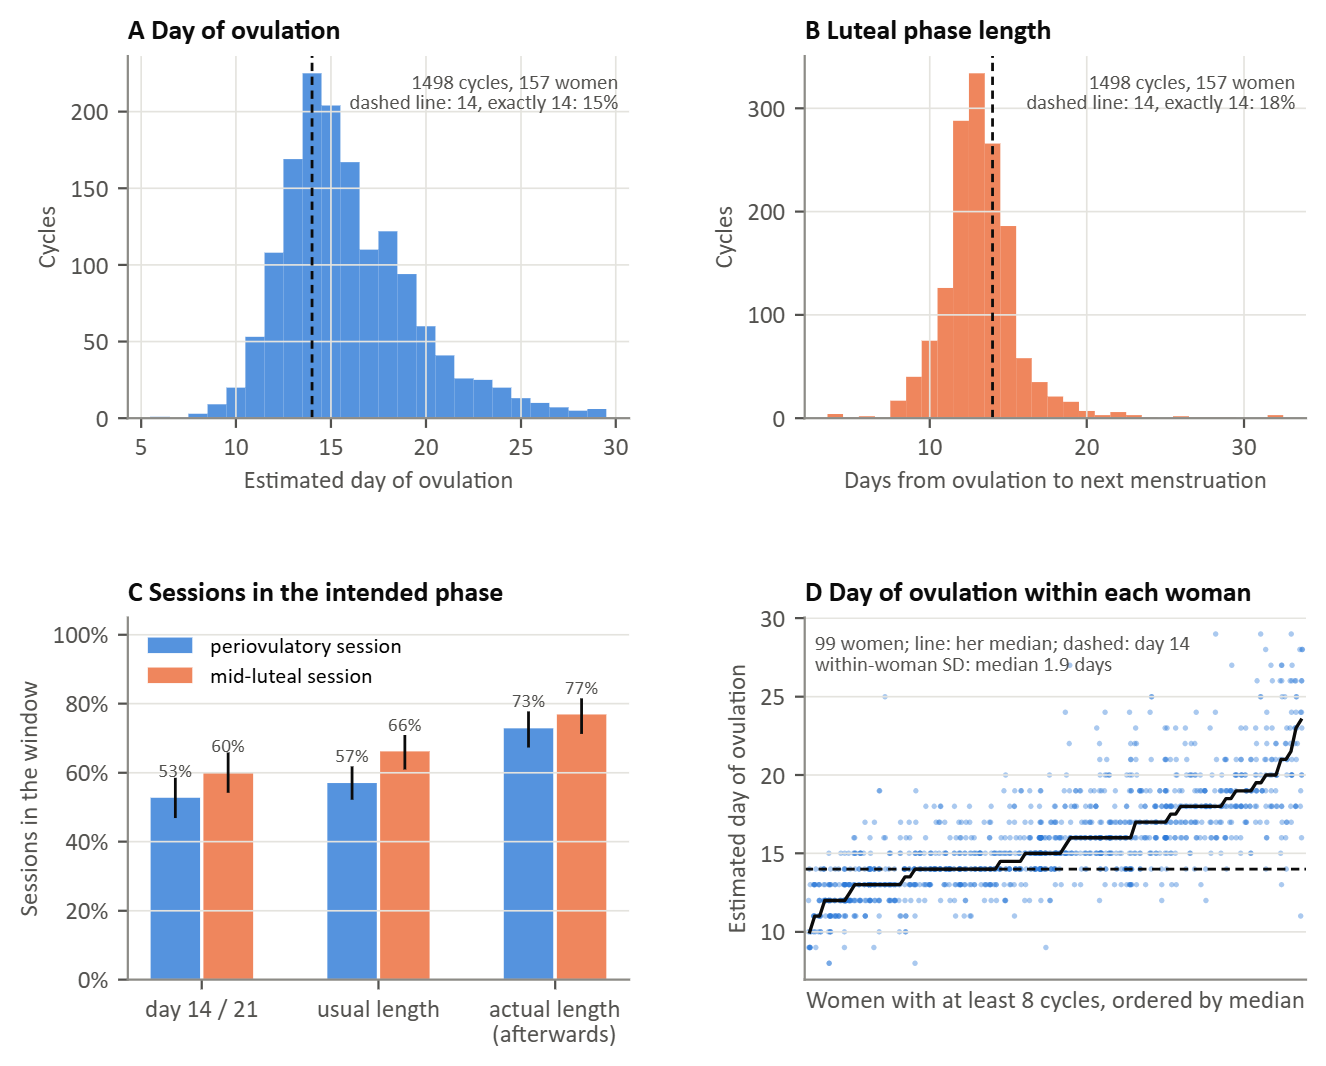

saved figures/cycle_day_counting.png


In [7]:
fig, ax = plt.subplots(2, 2, figsize=(7.6, 6.0))
fig.subplots_adjust(hspace=0.55, wspace=0.35)

for a, col, title, lab in ((ax[0, 0], "ovulation", "A  Day of ovulation", "Estimated day of ovulation"),
                           (ax[0, 1], "luteal", "B  Luteal phase length", "Days from ovulation to next menstruation")):
    v = C[col].values
    bins = np.arange(v.min() - 0.5, min(v.max(), 32) + 1.5)
    a.hist(np.clip(v, None, 32), bins=bins, color=BLUE if col == "ovulation" else ORANGE, alpha=0.85, lw=0)
    a.axvline(14, color=INK, lw=1, ls=(0, (3, 2)))
    share = (v == 14).mean()
    a.set(xlabel=lab, ylabel="Cycles", title=title)
    a.text(0.98, 0.95, f"{len(v)} cycles, {C.woman.nunique()} women\ndashed line: 14, exactly 14: {share:.0%}", transform=a.transAxes,
           ha="right", va="top", fontsize=7.5, color=INK2)

a = ax[1, 0]
x = np.arange(len(HIT))
for j, (key, col, lab) in enumerate((("ovulatory", BLUE, "periovulatory session"), ("luteal", ORANGE, "mid-luteal session"))):
    xx = x + (j - 0.5) * 0.3
    a.bar(xx, HIT[key], width=0.28, color=col, alpha=0.85, label=lab)
    a.errorbar(xx, HIT[key], yerr=[HIT[key] - HIT[f"{key}_lo"], HIT[f"{key}_hi"] - HIT[key]], fmt="none", ecolor=INK, lw=1)
    for xi, v in zip(xx, HIT[key]):
        a.text(xi, v + 0.06, f"{v:.0%}", ha="center", fontsize=7, color=INK2)
a.set_xticks(x, ["day 14 / 21", "usual length", "actual length\n(afterwards)"])
a.set(ylim=(0, 1.05), ylabel="Sessions in the window", title="C  Sessions in the intended phase")
a.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
a.grid(axis="x", visible=False)
a.legend(loc="upper left")

a = ax[1, 1]
many = C.groupby("woman").filter(lambda g: len(g) >= MIN_CYCLES_PLOT)
order = many.groupby("woman").ovulation.median().sort_values(kind="stable").index
pos = {w: i for i, w in enumerate(order)}
xj = many.woman.map(pos) + np.random.default_rng(SEED).uniform(-0.25, 0.25, len(many))
a.scatter(xj, many.ovulation, s=4, color=BLUE, alpha=0.45, lw=0)
a.plot(range(len(order)), many.groupby("woman").ovulation.median().loc[order].values, color=INK, lw=1.2)
a.axhline(14, color=INK, lw=1, ls=(0, (3, 2)))
sd_ov = many.groupby("woman").ovulation.std()
a.set(xlabel=f"Women with at least {MIN_CYCLES_PLOT} cycles, ordered by median", ylabel="Estimated day of ovulation",
      xlim=(-1, len(order)), title="D  Day of ovulation within each woman")
a.set_xticks([])
a.text(0.02, 0.95, f"{len(order)} women; line: her median; dashed: day 14\nwithin-woman SD: median {sd_ov.median():.1f} days", transform=a.transAxes,
       va="top", fontsize=7.5, color=INK2)
save(fig, "cycle_day_counting.png")

## Results file

In [8]:
def clean(v):
    if isinstance(v, dict):
        return {k: clean(x) for k, x in v.items()}
    if isinstance(v, (list, tuple, np.ndarray)):
        return [clean(x) for x in v]
    if isinstance(v, (np.floating, float)):
        return None if np.isnan(v) else float(f"{float(v):.4g}")
    if isinstance(v, np.integer):
        return int(v)
    return v


RES = {
    "dataset": "Marquette menstrual cycle data (FedCycleData071012.csv)",
    "n_cycles": len(C), "n_women": int(C.woman.nunique()), "n_cycles_with_history": len(H), "n_women_with_history": int(H.woman.nunique()),
    "variation": clean(VAR),
    "share_ovulation_day14": clean((C.ovulation == 14).mean()), "share_luteal_14": clean((C.luteal == 14).mean()),
    "ovulation_error": clean(ERR.to_dict("index")),
    "hit_rates": clean(HIT.to_dict("records")), "hit_rate_mid_luteal_by_arm": clean(by_arm),
    "day21_after_next_menses": clean(late),
    "women_with_8_cycles": len(sd_ov), "sd_ovulation_within_median": clean(sd_ov.median()),
    "windows": {"periovulatory": OVU_WINDOW, "mid_luteal": LUTEAL_WINDOW},
}
(RES_DIR / "cycle_day_counting.json").write_text(json.dumps(RES, indent=1))
print("saved results/cycle_day_counting.json")

saved results/cycle_day_counting.json
